# FIFA World Cup 2026 — Linear Regression 2.1
## 02. Exploratory Data Analysis (EDA)

**Objective:** Explore home-team goal difference and the eight existing pre-match predictors before regression modelling. This notebook follows the analysis sequence of the supplied 2.2 EDA notebook, adapted to **104 match-level rows (one row per match)**.

**Data policy:** Use the output of the original 2.1 Data Preparation notebook. Do not fill, replace, or recalculate historical values here; the separate 24-row historical review will be revisited later.

## Step 1 — Load and inspect the prepared dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
file_path = Path("Regression_2_1_Prepared_Data.csv")
if not file_path.exists():
    raise FileNotFoundError("Run the ORIGINAL 01_Data_Preparation_Regression_2_1 notebook first to create Regression_2_1_Prepared_Data.csv.")
df = pd.read_csv(file_path, parse_dates=["date"])
print("Loaded:", file_path.name)
print("Shape:", df.shape)
display(df.head())

Loaded: Regression_2_1_Prepared_Data.csv
Shape: (104, 14)


,match_id,date,Round_Number,Home_Team,Away_Team,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate,goal_difference
0,1,2026-06-11 19:00:00.000002931,1,Mexico,South Africa,0,0,0.0,0.0,0,0,0.0,0.0,2
1,2,2026-06-12 01:59:59.999997068,1,Korea Republic,Czechia,0,0,0.0,0.0,0,0,0.0,0.0,1
2,3,2026-06-12 19:00:00.000002931,1,Canada,Bosnia and Herzegovina,0,0,0.0,0.0,0,0,0.0,0.0,0
3,4,2026-06-13 01:00:00.000002931,1,USA,Paraguay,0,0,0.0,0.0,0,0,0.0,0.0,3
4,8,2026-06-13 19:00:00.000002931,1,Qatar,Switzerland,0,0,0.0,0.0,0,0,0.0,0.0,0


In [2]:
target = "goal_difference"
features = [
    "Team_prior_matches", "Opponent_prior_matches",
    "Team_prior_goals_scored_avg", "Opponent_prior_goals_scored_avg",
    "Team_rest_days", "Opponent_rest_days",
    "Team_prior_win_rate", "Opponent_prior_win_rate"
]
assert len(features) == 8 and all(c in df.columns for c in features + [target])
print("Target:", target)
print("Predictors:", *features, sep="\n- ")

Target: goal_difference
Predictors:
- Team_prior_matches
- Opponent_prior_matches
- Team_prior_goals_scored_avg
- Opponent_prior_goals_scored_avg
- Team_rest_days
- Opponent_rest_days
- Team_prior_win_rate
- Opponent_prior_win_rate


In [3]:
print("Rows:", len(df))
print("Unique match IDs:", df["match_id"].nunique())
print("Duplicate match IDs:", df["match_id"].duplicated().sum())
print("Teams represented:", len(set(df["Home_Team"]).union(df["Away_Team"])))
print("Date range:", df["date"].min(), "to", df["date"].max())
display(df.dtypes.to_frame("Data type"))

Rows: 104
Unique match IDs: 104
Duplicate match IDs: 0
Teams represented: 48
Date range: 2026-06-11 19:00:00.000002931 to 2026-07-19 19:00:00.000002931


,Data type
match_id,int64
date,datetime64[ns]
Round_Number,str
Home_Team,str
Away_Team,str
Team_prior_matches,int64
Opponent_prior_matches,int64
Team_prior_goals_scored_avg,float64
Opponent_prior_goals_scored_avg,float64
Team_rest_days,int64


In [4]:
missing = df[features + [target]].isna().sum().to_frame("Missing values")
display(missing)
print("Rows with at least one missing predictor:", df[features].isna().any(axis=1).sum())

,Missing values
Team_prior_matches,0
Opponent_prior_matches,0
Team_prior_goals_scored_avg,0
Opponent_prior_goals_scored_avg,0
Team_rest_days,0
Opponent_rest_days,0
Team_prior_win_rate,0
Opponent_prior_win_rate,0
goal_difference,0


Rows with at least one missing predictor: 0


## Step 2 — Descriptive statistics and target distribution

Goal difference is **signed**: positive means a home-team win, zero a draw, and negative an away-team win. Unlike goals scored, it can be negative.

In [5]:
display(df[features + [target]].describe().T)
summary = pd.DataFrame({
    "Count": df[features + [target]].count(),
    "Missing": df[features + [target]].isna().sum(),
    "Mean": df[features + [target]].mean(),
    "Median": df[features + [target]].median(),
    "Std dev": df[features + [target]].std(),
    "Skewness": df[features + [target]].skew()
})
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max
Team_prior_matches,104.0,1.903846,1.663540,0.0,1.0,2.000000,3.00,7.0
Opponent_prior_matches,104.0,1.903846,1.663540,0.0,1.0,2.000000,3.00,7.0
Team_prior_goals_scored_avg,104.0,1.362431,1.285058,0.0,0.0,1.000000,2.25,7.0
Opponent_prior_goals_scored_avg,104.0,1.296291,1.142627,0.0,0.0,1.000000,2.00,5.0
Team_rest_days,104.0,4.067308,2.466334,0.0,3.0,5.000000,6.00,9.0
Opponent_rest_days,104.0,4.048077,2.458904,0.0,3.0,5.000000,6.00,8.0
Team_prior_win_rate,104.0,0.365201,0.409446,0.0,0.0,0.000000,0.75,1.0
Opponent_prior_win_rate,104.0,0.330746,0.369031,0.0,0.0,0.333333,0.60,1.0
goal_difference,104.0,0.480769,2.024034,-4.0,-1.0,0.000000,2.00,6.0


,Count,Missing,Mean,Median,Std dev,Skewness
Team_prior_matches,104,0,1.904,2.000,1.664,0.930
Opponent_prior_matches,104,0,1.904,2.000,1.664,0.930
Team_prior_goals_scored_avg,104,0,1.362,1.000,1.285,1.068
Opponent_prior_goals_scored_avg,104,0,1.296,1.000,1.143,0.656
Team_rest_days,104,0,4.067,5.000,2.466,-0.689
Opponent_rest_days,104,0,4.048,5.000,2.459,-0.700
Team_prior_win_rate,104,0,0.365,0.000,0.409,0.465
Opponent_prior_win_rate,104,0,0.331,0.333,0.369,0.632
goal_difference,104,0,0.481,0.000,2.024,0.258


In [6]:
values = df[target].dropna()
print("Mean goal difference:", round(values.mean(), 3))
print("Median:", values.median())
print("Variance:", round(values.var(), 3))
print("Standard deviation:", round(values.std(), 3))
print("Skewness:", round(values.skew(), 3))
print("Home wins:", (values > 0).sum(), "| Draws:", (values == 0).sum(), "| Away wins:", (values < 0).sum())
display(values.value_counts().sort_index().rename_axis("Goal difference").to_frame("Matches"))

Mean goal difference: 0.481
Median: 0.0
Variance: 4.097
Standard deviation: 2.024
Skewness: 0.258
Home wins: 50 | Draws: 24 | Away wins: 30


,Matches
Goal difference,
-4,2
-3,6
-2,8
-1,14
0,24
1,21
2,15
3,7
4,3


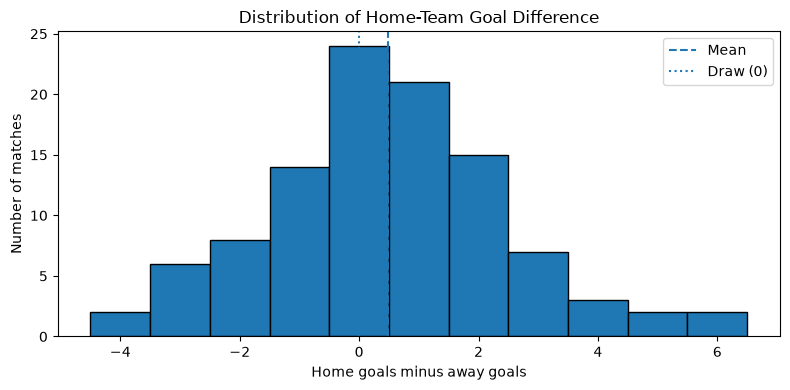

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\913837407.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


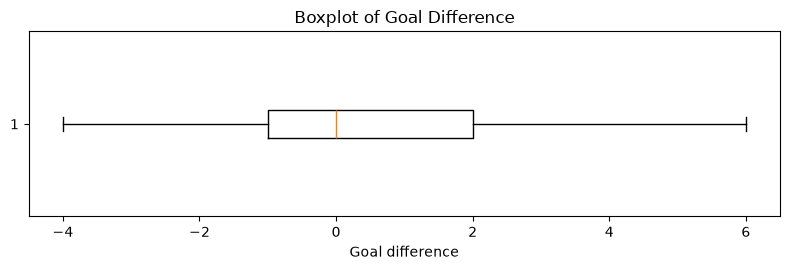

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(values, bins=np.arange(values.min()-0.5, values.max()+1.5, 1), edgecolor="black")
plt.axvline(values.mean(), linestyle="--", label="Mean")
plt.axvline(0, linestyle=":", label="Draw (0)")
plt.title("Distribution of Home-Team Goal Difference")
plt.xlabel("Home goals minus away goals")
plt.ylabel("Number of matches")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 2.8))
plt.boxplot(values, vert=False)
plt.title("Boxplot of Goal Difference")
plt.xlabel("Goal difference")
plt.tight_layout()
plt.show()

## Step 3 — Predictor distributions and possible outliers

Inspect the spread of all eight variables. An unusual value is not automatically an error; retain observations unless there is evidence that they are invalid.

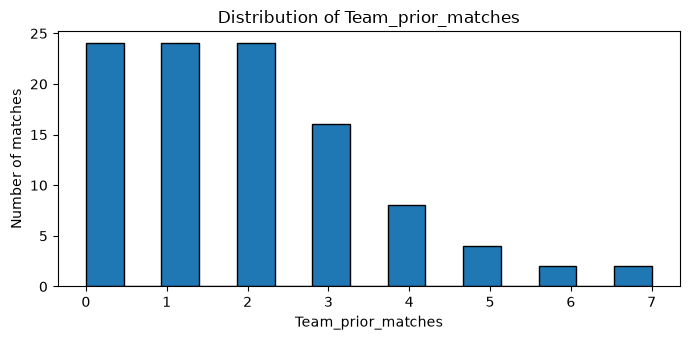

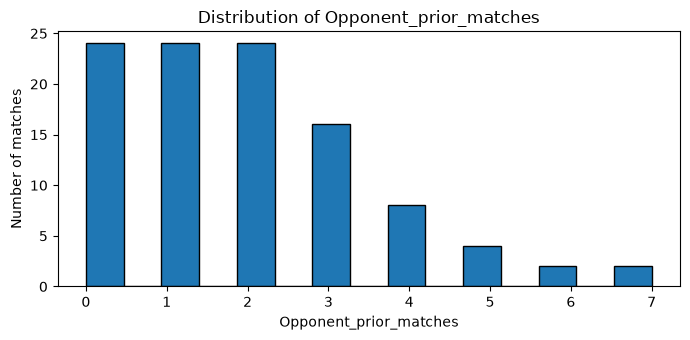

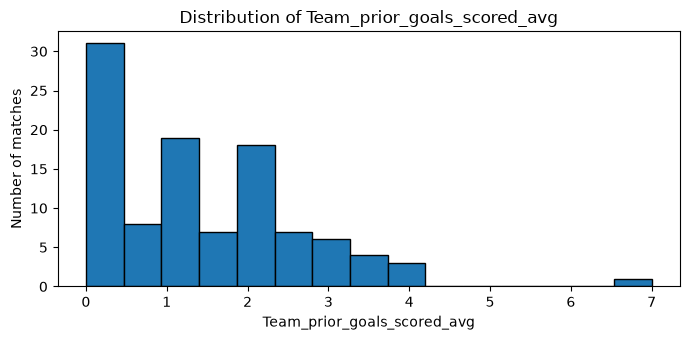

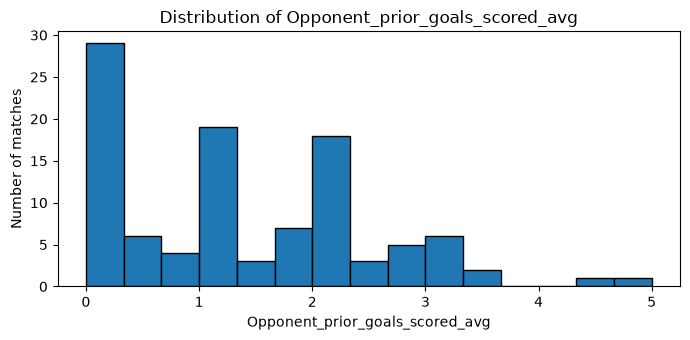

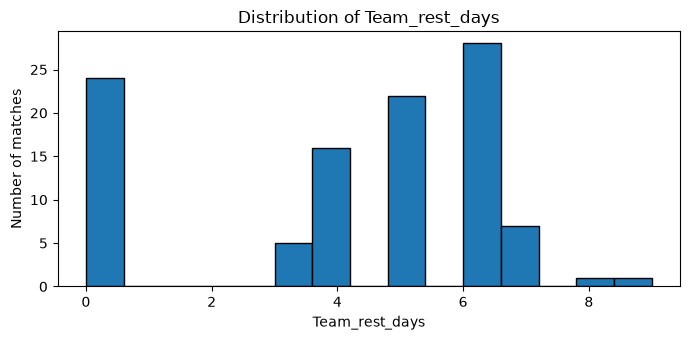

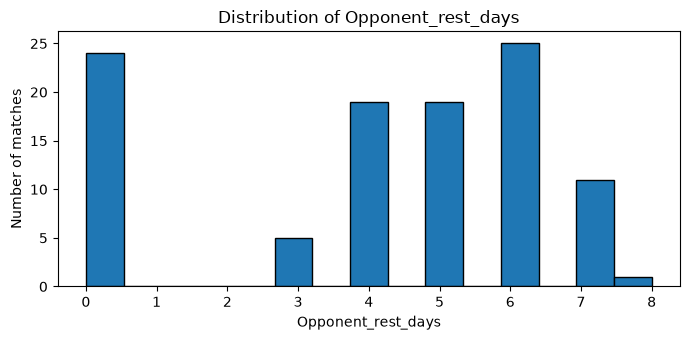

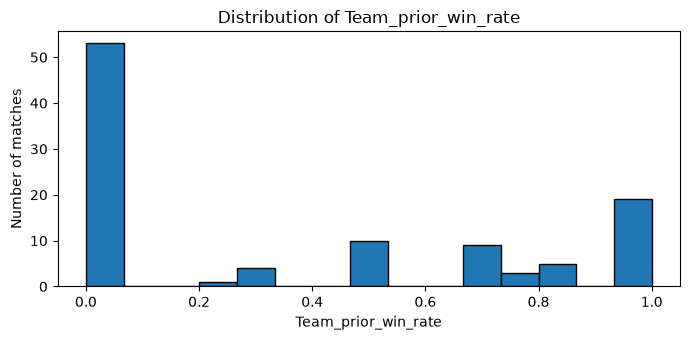

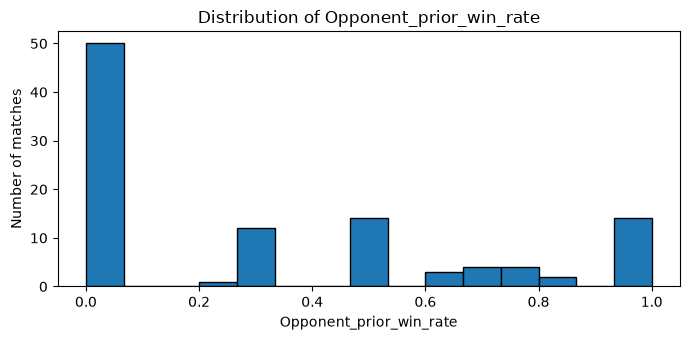

In [8]:
for feature in features:
    values = df[feature].dropna()
    plt.figure(figsize=(7, 3.5))
    plt.hist(values, bins=15, edgecolor="black")
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of matches")
    plt.tight_layout()
    plt.show()

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


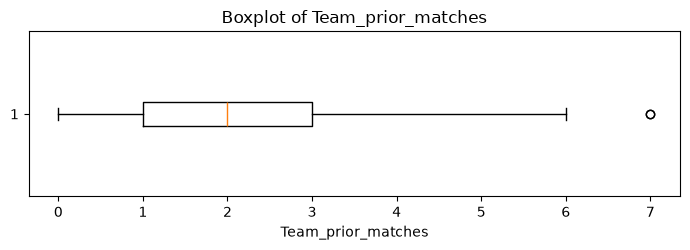

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


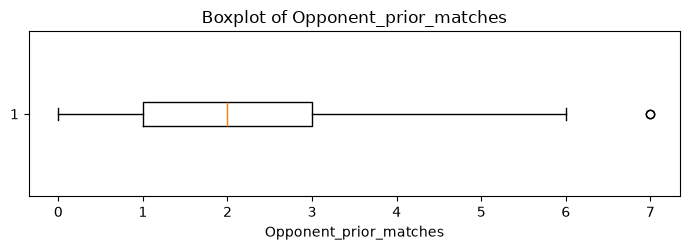

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


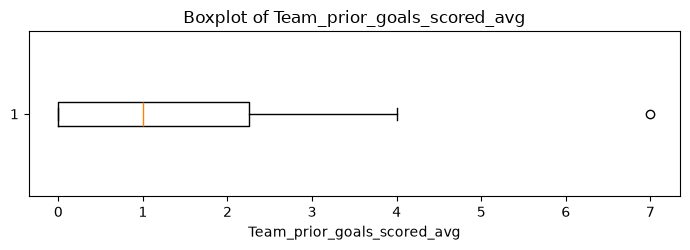

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


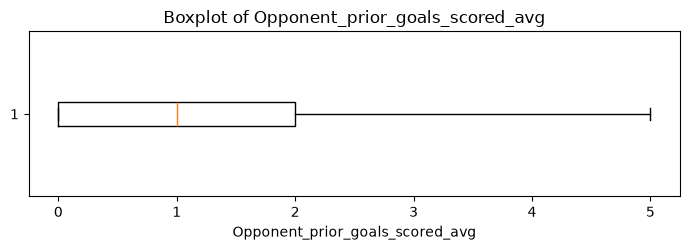

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


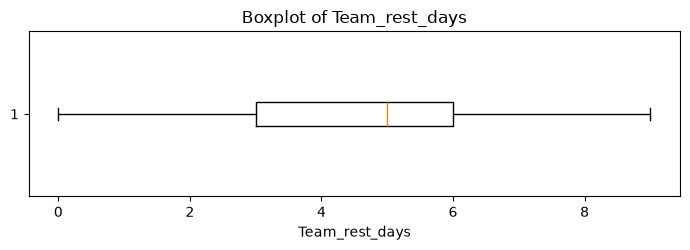

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


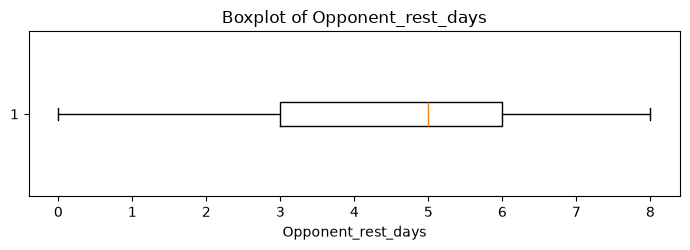

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


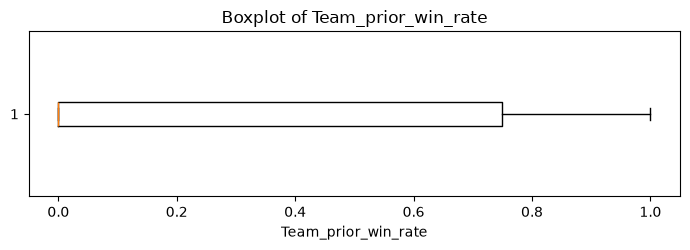

C:\Users\jelag\AppData\Local\Temp\ipykernel_23836\718897802.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


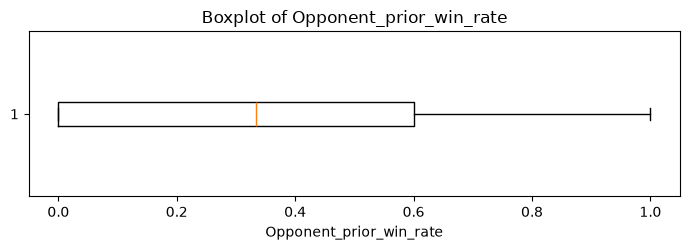

In [9]:
for feature in features:
    values = df[feature].dropna()
    if len(values):
        plt.figure(figsize=(7, 2.6))
        plt.boxplot(values, vert=False)
        plt.title(f"Boxplot of {feature}")
        plt.xlabel(feature)
        plt.tight_layout()
        plt.show()

In [10]:
outliers = []
for feature in features:
    values = df[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((values < lower) | (values > upper)).sum()
    outliers.append({"Predictor": feature, "Lower fence": lower, "Upper fence": upper, "Possible outliers": count})
display(pd.DataFrame(outliers).round(3))

,Predictor,Lower fence,Upper fence,Possible outliers
0,Team_prior_matches,-2.000,6.000,2
1,Opponent_prior_matches,-2.000,6.000,2
2,Team_prior_goals_scored_avg,-3.375,5.625,1
3,Opponent_prior_goals_scored_avg,-3.000,5.000,0
4,Team_rest_days,-1.500,10.500,0
5,Opponent_rest_days,-1.500,10.500,0
6,Team_prior_win_rate,-1.125,1.875,0
7,Opponent_prior_win_rate,-0.900,1.500,0


## Step 4 — Missing values and relationships

We report missing observations without imputing them. Correlations use complete pairs or complete cases as indicated; neither procedure changes the prepared dataset.

In [11]:
missing_rows = df.loc[df[features].isna().any(axis=1), ["match_id", "date", "Home_Team", "Away_Team"] + features]
print("Matches with missing predictor values:", len(missing_rows))
display(missing_rows.head(30))
complete_eda = df.dropna(subset=features + [target]).copy()
print("Complete-case matches for correlation:", len(complete_eda))

Matches with missing predictor values: 0


,match_id,date,Home_Team,Away_Team,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate


Complete-case matches for correlation: 104


,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate,goal_difference
Team_prior_matches,1.000,1.000,0.482,0.564,0.468,0.388,0.608,0.593,-0.214
Opponent_prior_matches,1.000,1.000,0.482,0.564,0.468,0.388,0.608,0.593,-0.214
Team_prior_goals_scored_avg,0.482,0.482,1.000,0.401,0.519,0.499,0.805,0.509,-0.009
Opponent_prior_goals_scored_avg,0.564,0.564,0.401,1.000,0.483,0.471,0.397,0.747,-0.178
Team_rest_days,0.468,0.468,0.519,0.483,1.000,0.939,0.401,0.399,-0.073
Opponent_rest_days,0.388,0.388,0.499,0.471,0.939,1.000,0.360,0.333,-0.110
Team_prior_win_rate,0.608,0.608,0.805,0.397,0.401,0.360,1.000,0.510,-0.039
Opponent_prior_win_rate,0.593,0.593,0.509,0.747,0.399,0.333,0.510,1.000,-0.233
goal_difference,-0.214,-0.214,-0.009,-0.178,-0.073,-0.110,-0.039,-0.233,1.000


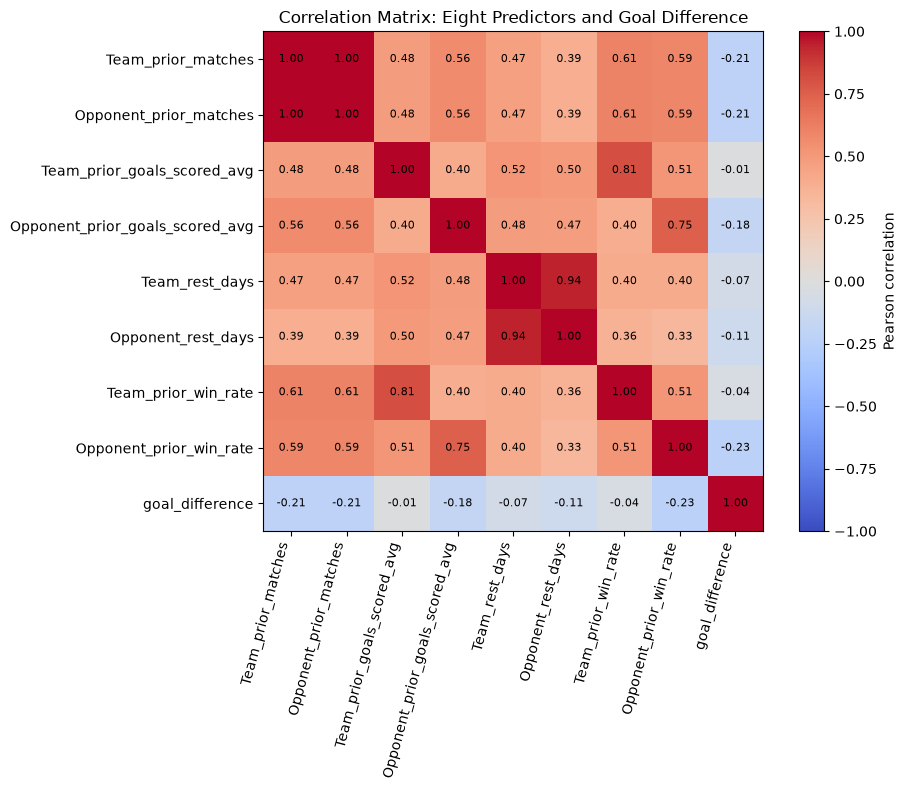

In [12]:
correlation_matrix = complete_eda[features + [target]].corr()
display(correlation_matrix.round(3))

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Pearson correlation")
labels = features + [target]
plt.xticks(range(len(labels)), labels, rotation=75, ha="right")
plt.yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation Matrix: Eight Predictors and Goal Difference")
plt.tight_layout()
plt.show()

In [13]:
predictor_corr = complete_eda[features].corr()
strong_pairs = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        r = predictor_corr.iloc[i, j]
        if abs(r) >= 0.7:
            strong_pairs.append({"Predictor 1": features[i], "Predictor 2": features[j], "Correlation": r})
print("Predictor pairs with |r| >= 0.70:")
display(pd.DataFrame(strong_pairs, columns=["Predictor 1", "Predictor 2", "Correlation"]))

Predictor pairs with |r| >= 0.70:


,Predictor 1,Predictor 2,Correlation
0,Team_prior_matches,Opponent_prior_matches,1.000000
1,Team_prior_goals_scored_avg,Team_prior_win_rate,0.805109
2,Opponent_prior_goals_scored_avg,Opponent_prior_win_rate,0.747203
3,Team_rest_days,Opponent_rest_days,0.939200


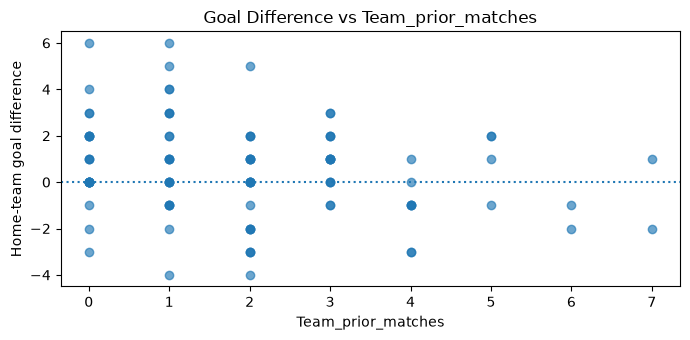

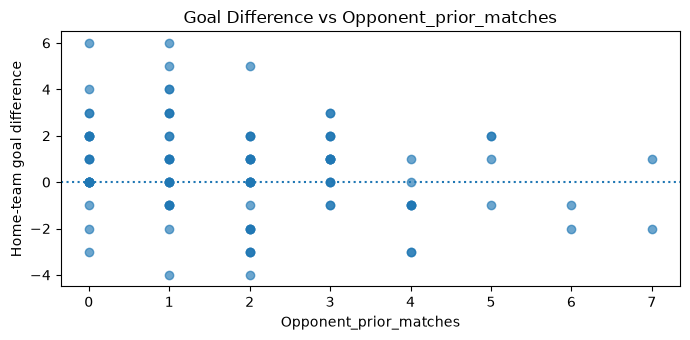

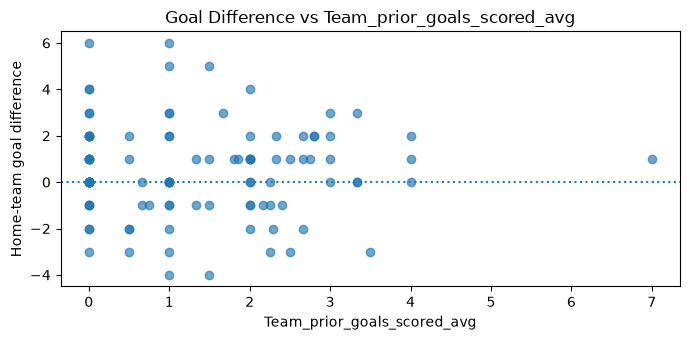

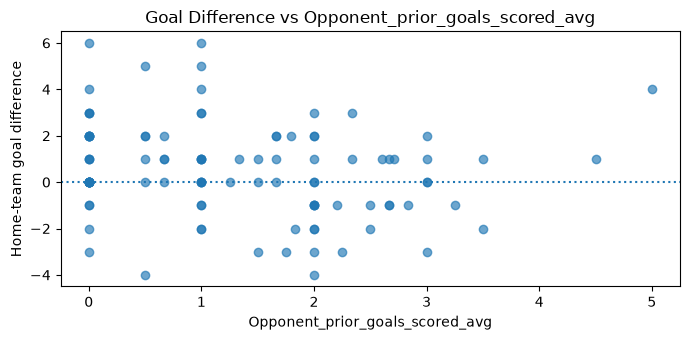

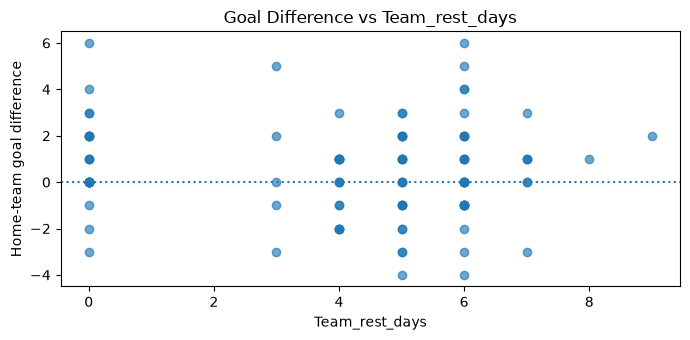

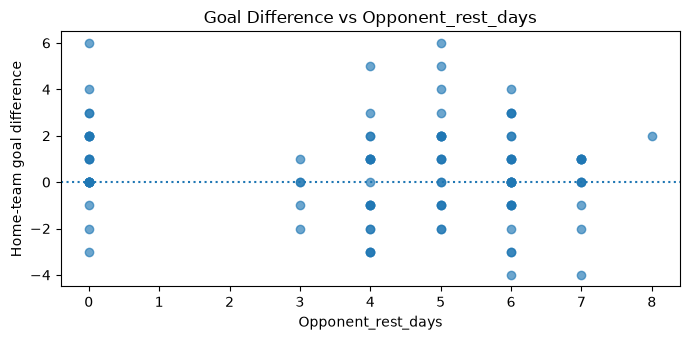

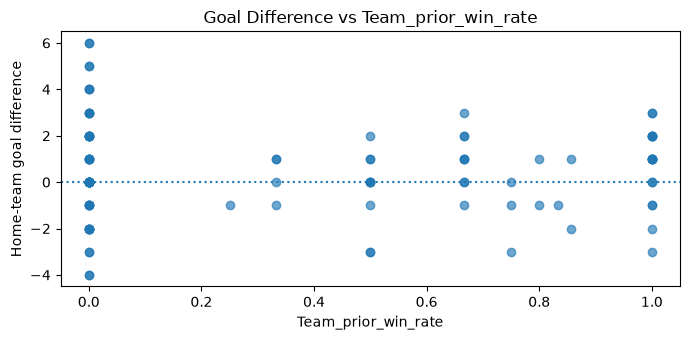

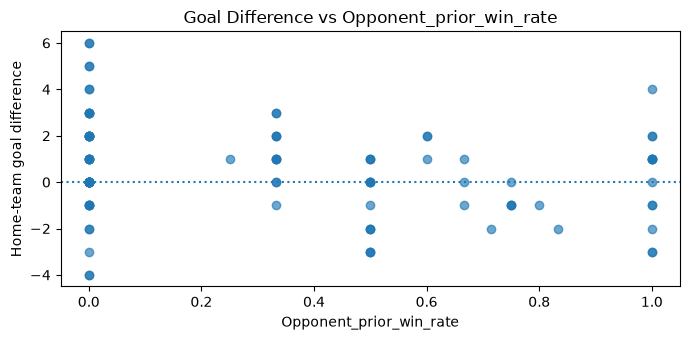

In [14]:
for feature in features:
    pair = df[[feature, target]].dropna()
    plt.figure(figsize=(7, 3.5))
    plt.scatter(pair[feature], pair[target], alpha=0.65)
    plt.axhline(0, linestyle=":")
    plt.title(f"Goal Difference vs {feature}")
    plt.xlabel(feature)
    plt.ylabel("Home-team goal difference")
    plt.tight_layout()
    plt.show()

In [15]:
target_corr = correlation_matrix[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False)
print("Predictor correlations with goal difference (ordered by absolute strength):")
display(target_corr.round(3).to_frame("Pearson r"))

Predictor correlations with goal difference (ordered by absolute strength):


,Pearson r
Opponent_prior_win_rate,-0.233
Team_prior_matches,-0.214
Opponent_prior_matches,-0.214
Opponent_prior_goals_scored_avg,-0.178
Opponent_rest_days,-0.110
Team_rest_days,-0.073
Team_prior_win_rate,-0.039
Team_prior_goals_scored_avg,-0.009


## Step 5 — Final EDA checks and summary

Unlike Regression 2.2, **each match contributes one row**, so there is no need to group two team observations per match. Do not drop rows or fill values in this EDA notebook.

In [ ]:
assert len(features) == 8
assert df["match_id"].is_unique, "Review repeated match identifiers."
assert df[target].notna().all(), "The target contains missing values."
print("Total matches:", len(df))
print("Complete-case matches:", len(complete_eda))
print("Rows with missing predictors:", df[features].isna().any(axis=1).sum())
print("Original dataset unchanged; no missing values filled and no outliers removed.")

Total matches: 104
Complete-case matches: 104
Rows with missing predictors: 0
Original dataset unchanged; no missing values filled and no outliers removed.


: 

### EDA interpretation checklist

After running the notebook, briefly discuss: (1) whether goal difference is centred near zero and whether it is skewed; (2) which predictors are most variable; (3) whether possible outliers represent plausible football outcomes; (4) the extent and location of missing predictor values; (5) the strongest predictor–target relationships; and (6) whether correlated predictors may affect ordinary linear regression.

**Next:** Regression Modelling 2.1. Any decisions about missing values, scaling, or model selection must be made within the modelling workflow without using information from the held-out test set.